<a href="https://colab.research.google.com/github/Art207141/Labs_sbor_analyz/blob/main/%D0%9B%D0%B0%D0%B1_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Подключение Google Диска и загрузка данных

In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import drive

# Подключаем Google Диск
drive.mount("/content/drive")

# Путь к файлу в папке "ДАТАСЕТЫ"
file_path = "/content/drive/MyDrive/ДАТАСЕТЫ/StudentsPerformance.csv"

# Загружаем датасет
df = pd.read_csv(file_path, quotechar='"')

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


# PANDAS

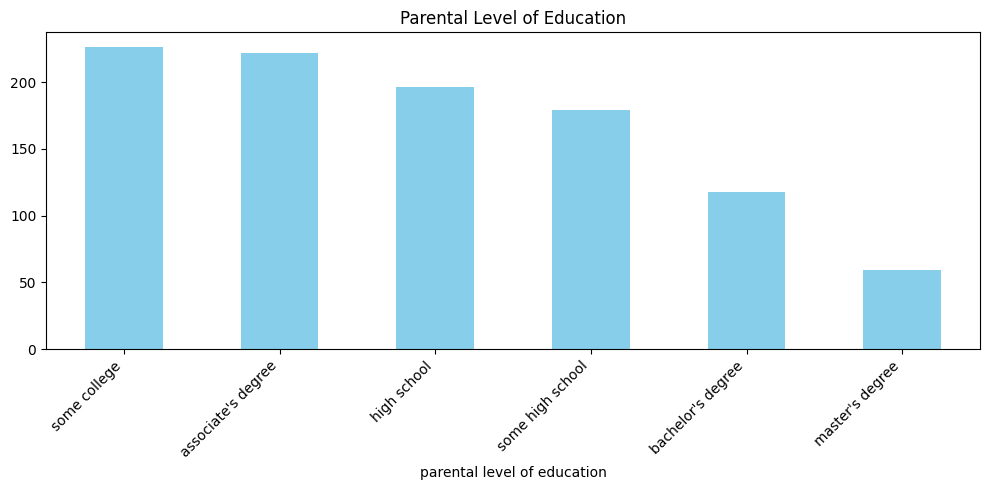

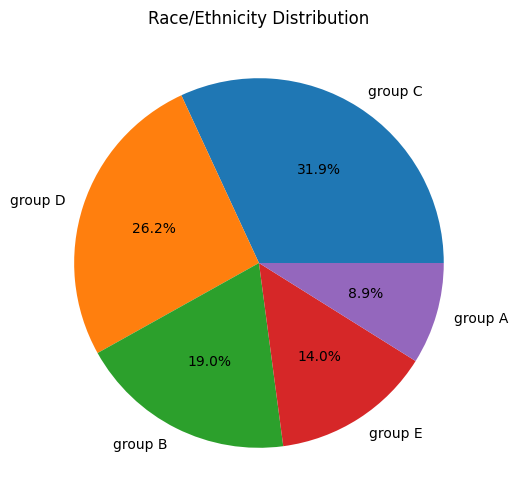

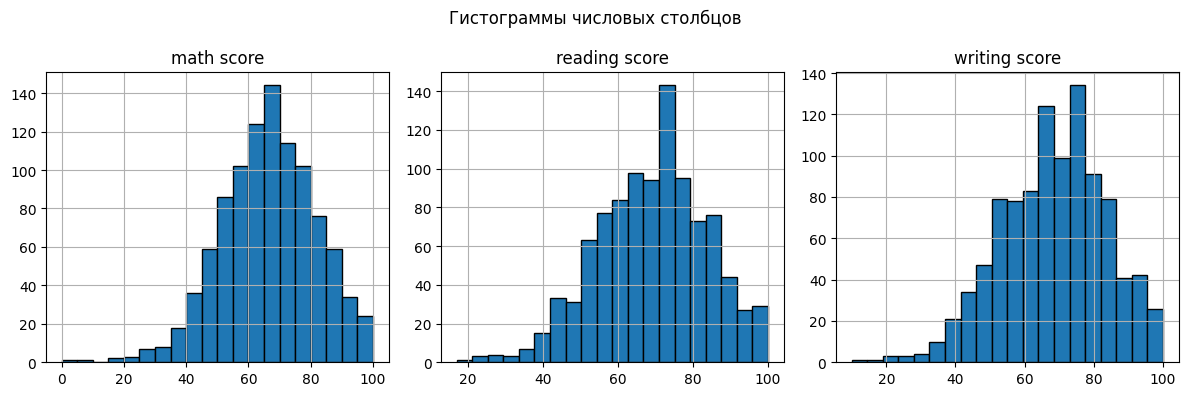

In [4]:
# 1. Столбчатая диаграмма для столбца parental level of education
plt.figure(figsize=(10, 5))
df["parental level of education"].value_counts().plot(kind="bar", color="skyblue")
plt.title("Parental Level of Education")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 2. Круговая диаграмма для столбца race/ethnicity
plt.figure(figsize=(6, 6))
df["race/ethnicity"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Race/Ethnicity Distribution")
plt.ylabel("")
plt.show()

# 3. Гистограммы для всех числовых столбцов (одним вызовом функции)
df.hist(figsize=(12, 4), layout=(1, 3), bins=20, edgecolor="black")
plt.suptitle("Гистограммы числовых столбцов")
plt.tight_layout()
plt.show()

# MATPLOTLIB

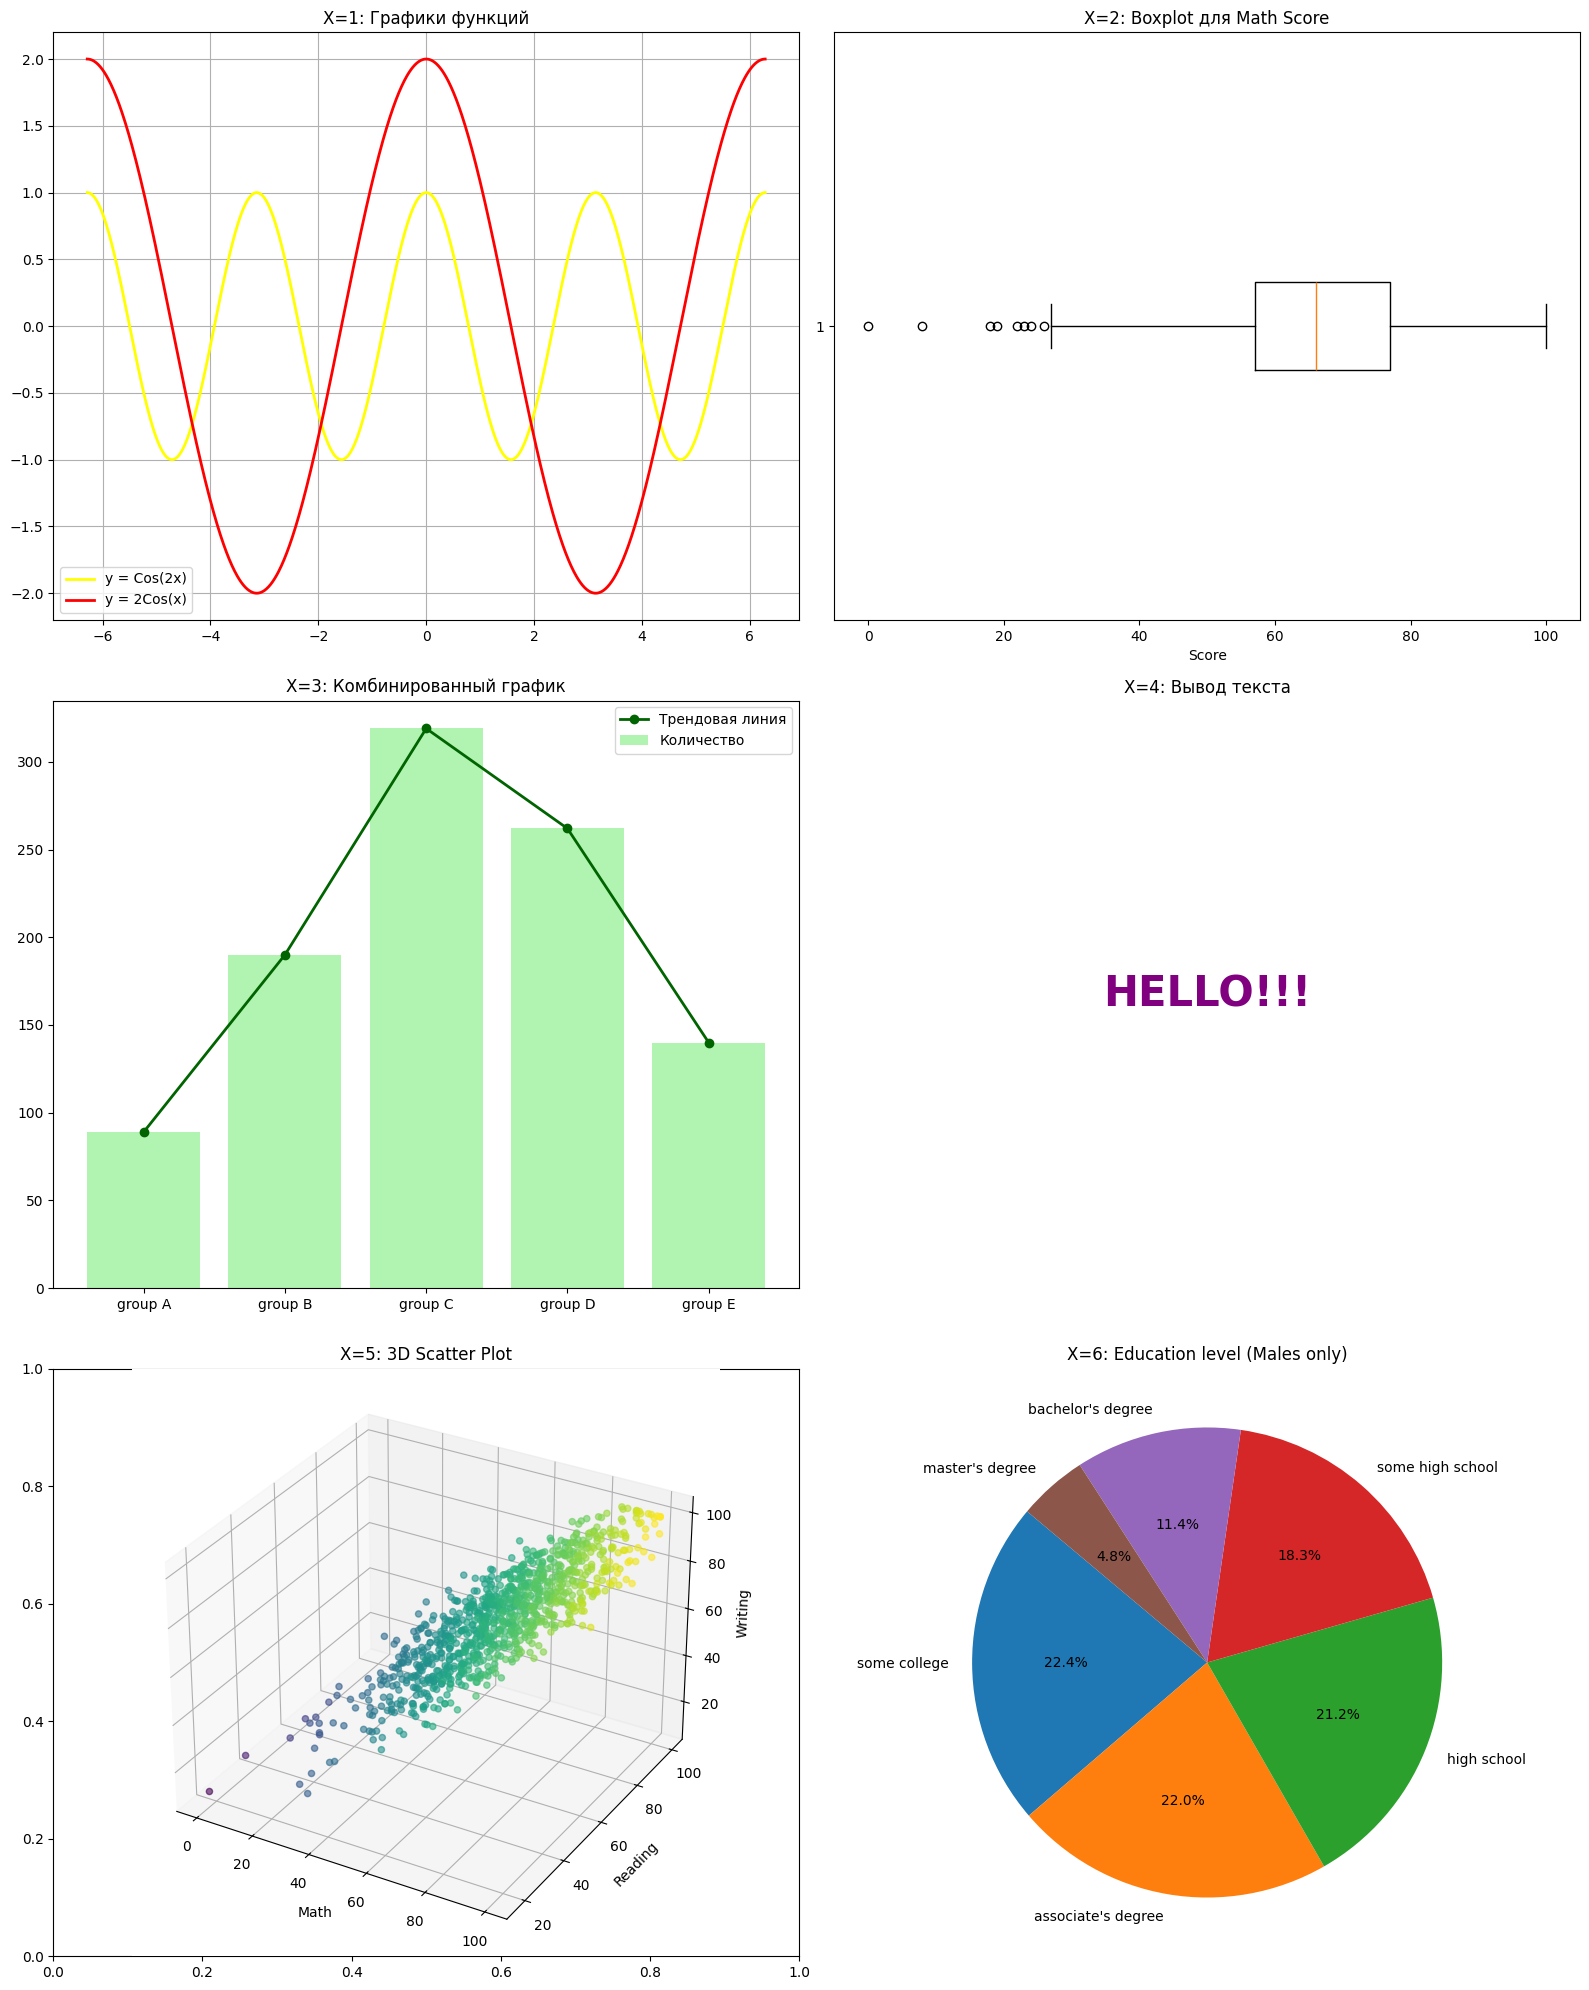

In [5]:
from mpl_toolkits.mplot3d import Axes3D

# Общее полотно 3 строки на 2 колонки
fig = plt.subplots(3, 2, figsize=(16, 20))

# --- X=1: Графики функций Cos(2x) и 2Cos(x) ---
ax1 = plt.subplot(3, 2, 1)
x = np.linspace(-2 * np.pi, 2 * np.pi, 1000)
y1 = np.cos(2 * x)
y2 = 2 * np.cos(x)
ax1.plot(x, y1, color="yellow", label="y = Cos(2x)", linewidth=2)
ax1.plot(x, y2, color="red", label="y = 2Cos(x)", linewidth=2)
ax1.grid(True)
ax1.set_title("X=1: Графики функций")
ax1.legend()

# --- X=2: Ящик с усами для math score ---
ax2 = plt.subplot(3, 2, 2)
ax2.boxplot(df["math score"], vert=False)
ax2.set_title("X=2: Boxplot для Math Score")
ax2.set_xlabel("Score")
# Ответ на вопрос в задании: Да, на графике будут видны точки слева от "усов" (обычно ниже 25-30 баллов),
# это экстремально низкие значения (выбросы).

# --- X=3: Комбинированный график для race/ethnicity ---
ax3 = plt.subplot(3, 2, 3)
counts = df["race/ethnicity"].value_counts().sort_index()
ax3.bar(counts.index, counts.values, color="lightgreen", alpha=0.7, label="Количество")
ax3.plot(counts.index, counts.values, color="darkgreen", marker="o", linewidth=2, label="Трендовая линия")
ax3.set_title("X=3: Комбинированный график")
ax3.legend()

# --- X=4: Текст HELLO!!! ---
ax4 = plt.subplot(3, 2, 4)
ax4.text(
    0.5,
    0.5,
    "HELLO!!!",
    fontsize=30,
    fontweight="bold",
    ha="center",
    va="center",
    color="purple",
)
ax4.set_title("X=4: Вывод текста")
ax4.axis("off")

# --- X=5: Диаграмма рассеяния 3D ---
# Для 3D графиков нужно явно переопределить проекцию оси
ax5 = plt.subplot(3, 2, 5, projection="3d")
ax5.scatter(
    df["math score"],
    df["reading score"],
    df["writing score"],
    c=df["math score"],
    cmap="viridis",
    alpha=0.6,
)
ax5.set_xlabel("Math")
ax5.set_ylabel("Reading")
ax5.set_zlabel("Writing")
ax5.set_title("X=5: 3D Scatter Plot")

# --- X=6: Круговая диаграмма для юношей ---
ax6 = plt.subplot(3, 2, 6)
# Фильтруем датасет только по юношам
male_df = df[df["gender"] == "male"]
male_education = male_df["parental level of education"].value_counts()
ax6.pie(male_education, labels=male_education.index, autopct="%1.1f%%", startangle=140)
ax6.set_title("X=6: Education level (Males only)")

plt.tight_layout()
plt.show()

# SEABORN

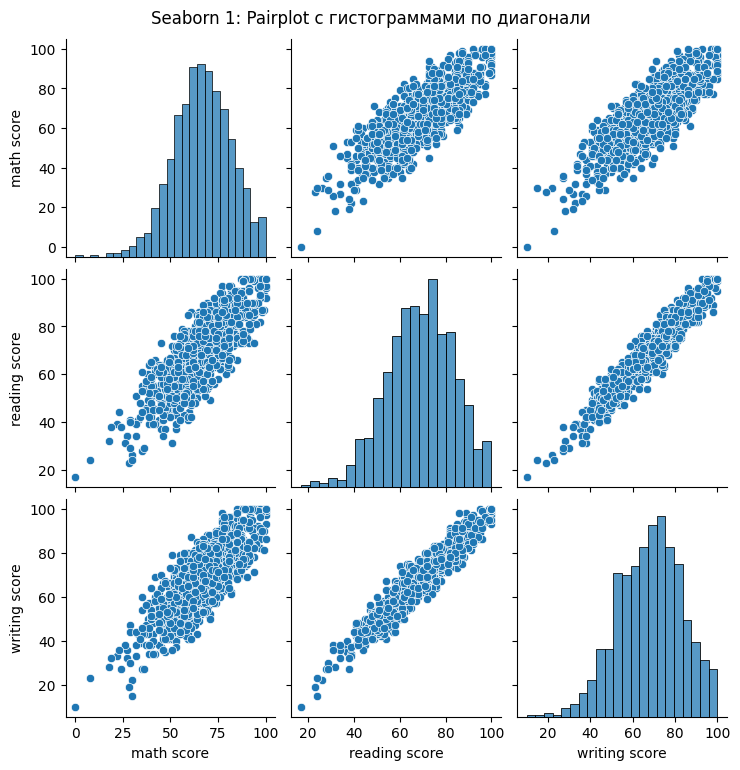

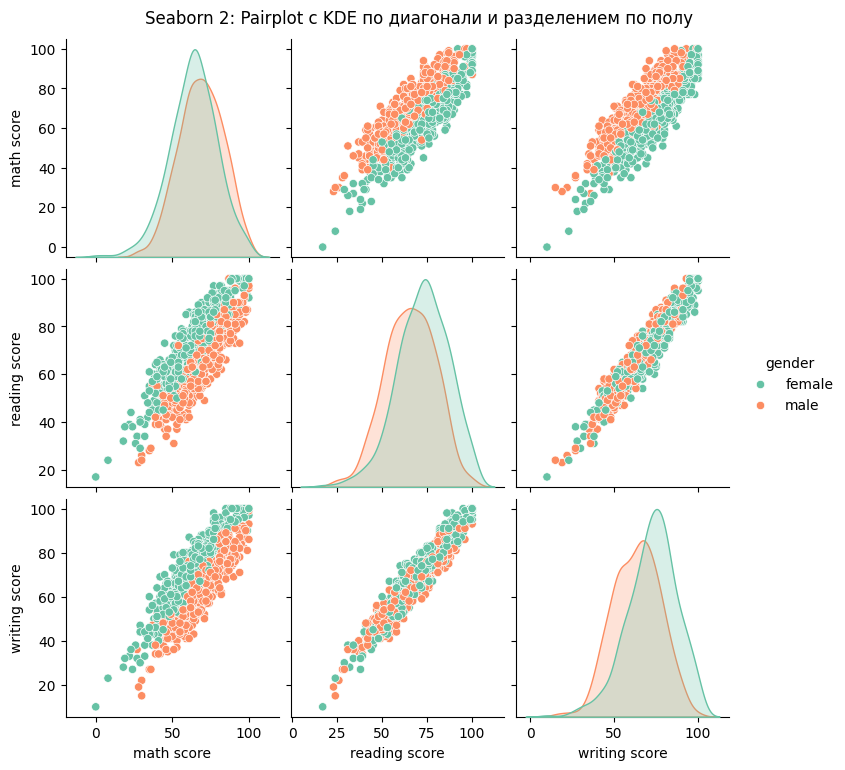

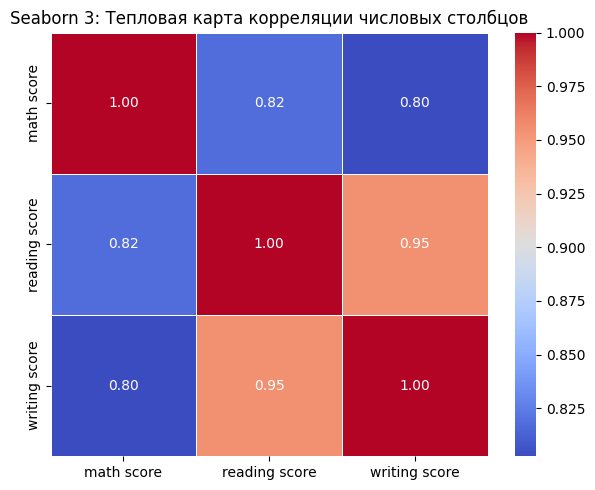

In [6]:
# 1. pairplot: Гистограммы по диагонали + диаграммы рассеяния
sns.pairplot(df, diag_kind="hist")
plt.suptitle(
    "Seaborn 1: Pairplot с гистограммами по диагонали", y=1.02
)  # y=1.02 приподнимает заголовок
plt.show()

# 2. pairplot: kde по диагонали + диаграммы рассеяния с кластеризацией по gender
sns.pairplot(df, diag_kind="kde", hue="gender", palette="Set2")
plt.suptitle(
    "Seaborn 2: Pairplot с KDE по диагонали и разделением по полу", y=1.02
)
plt.show()

# 3. Тепловая карта (Heatmap) для числовых столбцов
plt.figure(figsize=(6, 5))
# Отбираем только числовые столбцы и считаем корреляцию между ними
numeric_corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(numeric_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Seaborn 3: Тепловая карта корреляции числовых столбцов")
plt.tight_layout()
plt.show()